# 工程实践中的数学应用



## 一、Transformer 与注意力机制

### 1. 核心公式

Transformer 的缩放点积注意力（Scaled Dot-Product Attention）定义为：

$$
\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V
$$

其中：

* $Q$：Query，查询矩阵，表示当前词元需要寻找什么信息。
* $K$：Key，键矩阵，表示每个词元可以提供什么信息。
* $V$：Value，值矩阵，表示每个词元实际携带的内容。
* $d_k$：Key 向量的维度。
* $QK^T$：计算查询与各个键之间的点积相似度。
* $\operatorname{softmax}$：将相似度转换为归一化权重。
* 乘以 $V$：根据权重对各个词元的信息进行加权求和。

### 2. 计算过程

1. **计算相似度**：使用矩阵乘法 $QK^T$，获得所有查询与键之间的匹配分数。
2. **缩放分数**：除以 $\sqrt{d_k}$，避免点积随维度增大而过大。
3. **计算注意力权重**：对每一行执行 Softmax，得到权重分布。
4. **聚合信息**：使用注意力权重乘以 $V$，得到融合上下文信息的输出。

若有 $n$ 个词元，则注意力权重矩阵通常为 $n\times n$，描述每个词元对其他词元的关注程度。

### 3. 数学本质

* **线性代数**：通过矩阵乘法计算相似度并聚合信息。
* **概率论**：Softmax 生成归一化的非负权重，可以将其理解为一种权重分布。
* **加权平均**：输出是多个 Value 向量的加权组合。
* **非局部信息交互**：一个词元可以直接关注远距离的其他词元。

### 4. 与积分算子的联系

连续形式的非局部积分算子可以写成：

$$
y(x)=\int_{\Omega}K(x,z)v(z)\,dz
$$

其中 $K(x,z)$ 表示位置 $x$ 与位置 $z$ 之间的权重核。

离散化后，可以写成：

$$
y_i=\sum_{j=1}^{n}a_{ij}v_j
$$

其中 $a_{ij}$ 是归一化后的注意力权重。

因此，注意力机制可以看作一种**数据驱动的非局部加权聚合机制**，与积分算子具有数学上的联系。

需要注意：标准 Transformer 并不等同于某个积分—微分方程的离散化形式。只有在特定的连续模型或算子学习框架下，才能建立更具体的对应关系。

### 5. 工程应用

* 大语言模型：根据上下文生成下一个词元。
* 图像识别：建立图像不同区域之间的联系。
* 时间序列预测：捕捉不同时间点之间的依赖关系。
* AI 智能体：结合历史上下文与当前输入，提取相关信息。

**数学关键词：矩阵乘法、向量相似度、Softmax、加权求和、非局部算子。**

---

## 二、Adam 优化器：一阶动量与二阶矩估计

### 1. 核心思想

Adam（Adaptive Moment Estimation）是一种自适应学习率优化算法。

它结合了：

* **一阶动量**：平滑梯度方向，减弱梯度噪声。
* **二阶矩估计**：根据梯度平方的历史大小，自适应调整每个参数的更新幅度。
* **偏差修正**：缓解初始时刻动量估计偏向零的问题。

### 2. 数学公式

设第 $t$ 步的梯度为：

$$
g_t=\nabla_\theta L(\theta_t)
$$

一阶矩估计：

$$
m_t=\beta_1m_{t-1}+(1-\beta_1)g_t
$$

二阶原始矩估计：

$$
v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2
$$

偏差修正：

$$
\hat m_t=\frac{m_t}{1-\beta_1^t},\qquad \hat v_t=\frac{v_t}{1-\beta_2^t}
$$

参数更新：

$$
\theta_{t+1}=\theta_t-\eta\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}
$$

这里的平方、平方根和除法通常都是逐元素运算。

### 3. 符号说明

| 符号                  | 含义           |
| ------------------- | ------------ |
| $\theta_t$          | 第 $t$ 步的模型参数 |
| $L(\theta_t)$       | 当前损失函数       |
| $g_t$               | 当前梯度         |
| $m_t$               | 梯度的一阶矩估计     |
| $v_t$               | 梯度平方的二阶原始矩估计 |
| $\hat m_t,\hat v_t$ | 偏差修正后的矩估计    |
| $\eta$              | 基础学习率        |
| $\beta_1,\beta_2$   | 指数移动平均的衰减系数  |
| $\epsilon$          | 防止分母过小的稳定常数  |

### 4. 一阶方法、二阶方法与 Adam 的区别

| 方法       | 使用的信息          | 主要特点          |
| -------- | -------------- | ------------- |
| 梯度下降（GD） | 一阶梯度           | 沿负梯度方向更新      |
| 牛顿法      | 梯度与 Hessian 矩阵 | 利用局部曲率调整更新方向  |
| Adam     | 一阶动量与梯度平方的移动平均 | 自适应调整各参数的更新幅度 |

牛顿法的典型更新为：

$$
\theta_{t+1}=\theta_t-H_t^{-1}g_t
$$

其中 $H_t=\nabla^2 L(\theta_t)$ 是 Hessian 矩阵。实际实现通常求解线性方程组，而不是显式计算逆矩阵。

**重要区别：Adam 的二阶矩不等于二阶导数，也不等于 Hessian。** 它没有直接计算目标函数的曲率，因此不能据此声称 Adam 达到了牛顿法的二阶收敛速度。

### 5. Adam 为什么有用？

1. 梯度方向变化较大时，一阶动量可以平滑更新。
2. 不同参数的梯度尺度不同时，二阶矩估计可以调整它们的有效步长。
3. 在深度学习中，通常不需要构建和求解巨大的 Hessian 系统。

例如，机械臂控制模型中的不同参数可能具有不同的数值尺度。Adam 可以根据各参数的梯度历史调整更新幅度，但它并不会让机械臂拥有自我意识，也不能直接判断下一步物理动作是否安全。

**数学关键词：梯度下降、指数移动平均、自适应学习率、数值优化。**

---

## 三、矩阵分解与推荐系统

### 1. 核心思想

推荐系统需要预测用户对尚未评价的物品可能有多大兴趣。

假设评分矩阵为：

$$
R\in\mathbb{R}^{n_u\times n_i}
$$

其中：

* $n_u$：用户数量。
* $n_i$：物品数量。
* $R_{ui}$：用户 $u$ 对物品 $i$ 的评分。

真实评分矩阵通常非常稀疏，因为用户不可能评价所有物品。

矩阵分解将其近似表示为两个低秩矩阵的乘积：

$$
R\approx UV^T
$$

其中：

$$
U\in\mathbb{R}^{n_u\times d},\qquad V\in\mathbb{R}^{n_i\times d}
$$

这里使用 $n_u,n_i$ 表示数量，避免与用户隐向量矩阵 $U$ 的符号混淆。

### 2. 如何预测评分？

用户 $u$ 的隐向量记为 $p_u$，物品 $i$ 的隐向量记为 $q_i$。

预测评分为：

$$
\hat R_{ui}=p_u^Tq_i
$$

直观理解：

* 用户向量表示用户的潜在兴趣。
* 物品向量表示物品的潜在属性。
* 两个向量的内积越大，模型预测的匹配程度通常越高。

这些隐向量中的维度不一定对应可直接解释的现实属性。

### 3. 数值优化如何参与？

一种常见的训练目标是最小化已观测评分的重构误差，并对模型复杂度进行约束：

$$
\min_{U,V}\sum_{(u,i)\in\Omega}(R_{ui}-p_u^Tq_i)^2+\lambda(\|U\|_F^2+\|V\|_F^2)
$$

其中：

* $\Omega$：已观测评分的索引集合。
* $\lambda$：正则化系数。
* $|\cdot|_F$：Frobenius 范数。

只对已观测评分进行训练，可以避免把缺失评分直接当成真实的零分。

### 4. 数学本质

* **线性代数**：低秩矩阵近似、向量内积。
* **数值优化**：最小化重构误差。
* **统计学习**：从稀疏观测中学习潜在偏好。
* **表示学习**：将用户和物品映射到低维向量空间。

### 5. 与图神经网络结合

在用户—物品交互图中：

1. 用户和物品作为节点。
2. 点击、购买、评分等行为作为边。
3. 图神经网络逐层聚合邻居节点的信息。
4. 得到增强后的用户和物品嵌入表示。
5. 通过向量内积或其他评分函数生成推荐结果。

图神经网络推荐不只是矩阵分解的另一种写法，它还显式利用了图结构和邻居关系。

**数学关键词：低秩近似、向量内积、最小二乘、正则化、图表示学习。**

---

## 四、PageRank 与马尔可夫链

### 1. 马尔可夫链的基本思想

马尔可夫链是一种随机过程，其下一步状态在给定当前状态后，不再额外依赖更早的历史状态。

其马尔可夫性质可以表示为：

$$
P(X_{t+1}\mid X_t,X_{t-1},\ldots,X_0)=P(X_{t+1}\mid X_t)
$$

对于离散状态空间，转移概率矩阵 $P$ 描述状态之间的转移关系。

采用行随机矩阵约定时：

$$
P_{ij}=P(X_{t+1}=j\mid X_t=i)
$$

每一行满足：

$$
\sum_jP_{ij}=1,\qquad P_{ij}\geq0
$$

### 2. 平稳分布

设 $\pi$ 是行向量，表示系统处于各个状态的概率分布。

如果：

$$
\pi P=\pi
$$

那么 $\pi$ 就是转移矩阵 $P$ 对应的一个平稳分布。

同时满足：

$$
\sum_i\pi_i=1,\qquad \pi_i\geq0
$$

直观理解：如果系统初始状态分布已经是 $\pi$，经过一次状态转移后，分布仍然是 $\pi$。

这并不意味着每个个体都停止移动，而是指整体概率分布保持不变。

### 3. PageRank 的核心思想

PageRank 将网页视为节点，将网页之间的链接视为有向边。

一个网页的重要程度不仅取决于它有多少入链，还取决于链接来源网页的重要程度。

采用行向量约定，PageRank 可以表示为：

$$
\pi=\alpha\pi P+(1-\alpha)v
$$

其中：

* $P$：处理悬挂节点后的网页转移矩阵。
* $\pi$：网页的 PageRank 分布。
* $\alpha$：继续沿链接转移的概率。
* $v$：随机跳转分布，通常取均匀分布。

随机跳转机制可以避免部分网页结构造成的陷阱，并有助于获得稳定的排名分布。

### 4. 数学本质

* **线性代数**：平稳分布满足特征向量形式的关系。
* **概率论**：使用转移概率描述随机过程。
* **图论**：网页链接形成有向图。
* **数值算法**：通过迭代计算 PageRank。

### 5. 连续时间马尔可夫链

连续时间马尔可夫链使用生成矩阵 $Q$，而不是直接把离散转移概率矩阵乘以一个常数。

对于常见的行向量约定，生成矩阵满足：

$$
q_{ij}\geq0\quad(i\ne j),\qquad \sum_jq_{ij}=0
$$

因此对角元素为：

$$
q_{ii}=-\sum_{j\ne i}q_{ij}
$$

转移概率矩阵随时间变化为：

$$
P(t)=e^{tQ}
$$

其中 $q_{ij}$ 表示从状态 $i$ 跳转到状态 $j$ 的瞬时速率。

如果需要由离散转移矩阵 $P$ 构造连续时间过程，一种常见的均匀化形式为：

$$
Q=\lambda(P-I)
$$

其中 $\lambda$ 是非负速率常数，$I$ 是单位矩阵。该构造要求 $P$ 是合法的行随机矩阵。

因此，$Q=kP$ 一般不成立，因为它通常无法满足生成矩阵的行和为零这一条件。

### 6. 工程应用

* 网页排序与链接分析。
* 用户行为路径建模。
* 风险传播与异常关系分析。
* 反洗钱场景中的交易网络分析。
* 图嵌入和图神经网络中的随机游走。

需要注意：PageRank 本身不是无监督节点嵌入算法，但它可以作为图分析和节点重要性评估的一种基础方法。

**数学关键词：马尔可夫性质、随机游走、平稳分布、特征向量、图论。**

---

## 五、椭圆曲线密码与后量子密码

### 1. 椭圆曲线密码 ECC

椭圆曲线密码（Elliptic Curve Cryptography，ECC）基于椭圆曲线上的点运算构造密码系统。

在有限域上，一条常见的椭圆曲线可以写成：

$$
y^2\equiv x^3+ax+b\pmod p
$$

其中 $p$ 通常为素数，并且曲线需要满足非奇异条件。

ECC 的安全性通常依赖椭圆曲线离散对数问题（ECDLP）的计算困难性。

已知椭圆曲线上的基点 $G$ 和公钥：

$$
Q=dG
$$

其中 $d$ 是私钥，$Q$ 是公钥。

在适当选择的曲线和参数下，从 $G,Q$ 求出 $d$ 在经典计算机上被认为很困难。

### 2. 为什么需要后量子密码？

大规模、容错的量子计算机如果能够实现 Shor 算法，将对目前基于整数分解和离散对数困难性的 RSA、传统 ECC 等密码系统构成重大威胁。

后量子密码（PQC）研究的是能够抵抗已知量子计算攻击的密码算法。

常见研究方向包括：

* **格密码**：利用特定格问题的计算困难性。
* **哈希密码**：利用密码学哈希函数构造签名。
* **纠错码密码**：利用编码理论中的困难问题。
* **多变量密码**：利用多变量多项式系统相关的困难问题。
* **同源密码**：利用椭圆曲线之间的特定同源映射构造密码方案。

### 3. 同源密码的理解

同源密码不是简单地在两个椭圆曲线之间寻找任意一个同态映射，而是利用具有特定结构和安全假设的同源问题构造密码系统。

著名的 SIDH/SIKE 方案已被经典攻击破解，不能作为当前安全后量子密码的推荐方案。

工程实践中应优先关注经过标准化和安全评估的后量子密码算法，例如基于格的 ML-KEM、ML-DSA 等标准化方案。

### 4. 数学基础

* 数论：整数、素数、有限域。
* 模运算：处理有限域上的运算。
* 抽象代数：群、环、域与群上的运算。
* 计算复杂性：分析某类问题的求解难度。

**数学关键词：有限域、群论、模运算、离散对数、计算复杂性。**

---

## 六、傅里叶变换与信号处理

### 1. 核心思想

傅里叶变换的核心是：

> 将信号从时间或空间表示转换到频率表示，分析其中包含哪些频率成分，以及各成分的幅度和相位。

时域描述信号随时间如何变化；频域描述不同频率成分如何构成信号。

### 2. 连续傅里叶变换

采用频率 $\nu$（单位通常为 Hz）的约定，连续傅里叶变换为：

$$
\hat f(\nu)=\int_{-\infty}^{\infty}f(t)e^{-2\pi i\nu t}\,dt
$$

其中：

* $f(t)$：时域信号。
* $\hat f(\nu)$：频域表示。
* $\nu$：频率。
* $i$：虚数单位。

通过复指数基函数，可以表示信号的频率成分。

在满足相应条件时，可以利用逆变换恢复原始信号：

$$
f(t)=\int_{-\infty}^{\infty}\hat f(\nu)e^{2\pi i\nu t}\,d\nu
$$

### 3. 离散傅里叶变换 DFT

对于长度为 $N$ 的离散序列 $x_n$，DFT 定义为：

$$
X_k=\sum_{n=0}^{N-1}x_ne^{-2\pi i kn/N}
$$

其中 $k=0,1,\ldots,N-1$。

* $x_n$：时域离散采样值。
* $X_k$：第 $k$ 个频率索引对应的复数系数。
* $|X_k|$：频率分量的幅度。
* $\arg(X_k)$：频率分量的相位。

这里的 $k$ 是离散频率索引，不直接等同于以 Hz 表示的实际频率。对于采样率为 $f_s$ 的信号，频率索引对应的频率为 $kf_s/N$，但实际解释还需考虑频率混叠和正负频率的对应关系。

### 4. DFT 与 FFT 的区别

DFT 是数学变换；FFT（Fast Fourier Transform）是高效计算 DFT 的一类算法。

朴素计算 DFT 的复杂度为：

$$
O(N^2)
$$

对于适合使用标准 FFT 算法的长度，计算复杂度通常可以达到：

$$
O(N\log N)
$$

因此：

$$
\boxed{O(N^2)\longrightarrow O(N\log N)}
$$

表示的是计算算法的复杂度优化，而不是傅里叶变换定义发生了改变。

### 5. 数学本质

* **线性代数**：可以将 DFT 理解为向量乘以一个复数矩阵。
* **复数**：复指数同时表达振幅与相位。
* **函数逼近**：用不同频率的复指数成分表示信号。
* **算法设计**：FFT 利用分治和周期性降低计算成本。
* **微积分**：连续傅里叶变换涉及积分与函数空间。

### 6. AI 工程中的应用

* 语音识别：提取频谱或 Mel 频谱特征。
* 音频处理：分析音高、噪声与谐波。
* 图像处理：研究图像中的空间频率。
* 时间序列预测：提取周期性和季节性特征。
* 科学计算：加速卷积和部分微分方程数值求解。

**数学关键词：积分、复数、正交基、频域分析、分治算法。**

---

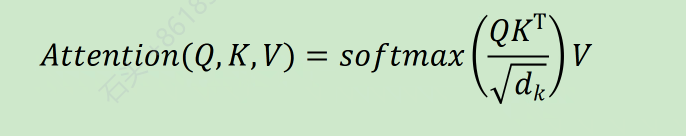
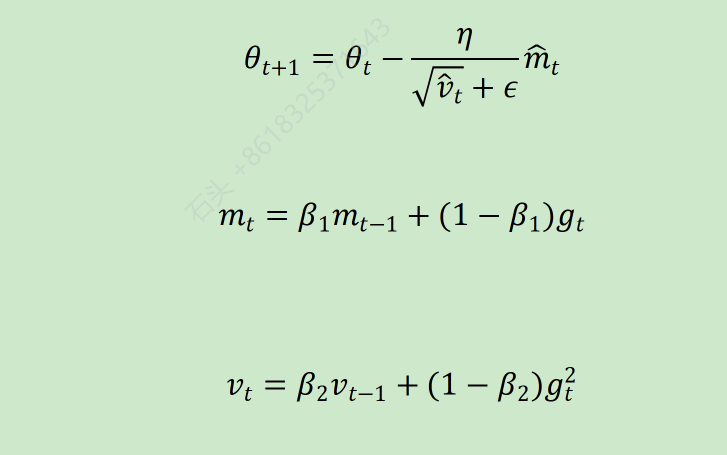
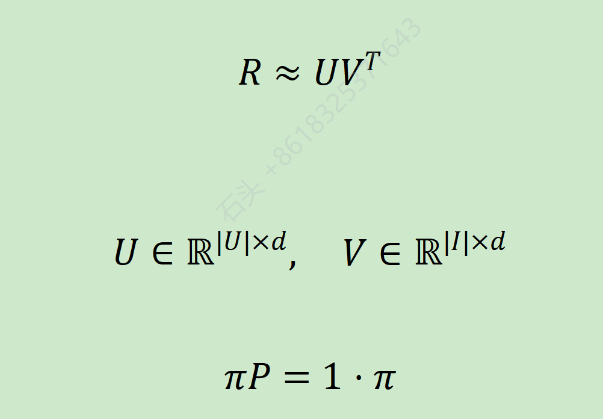
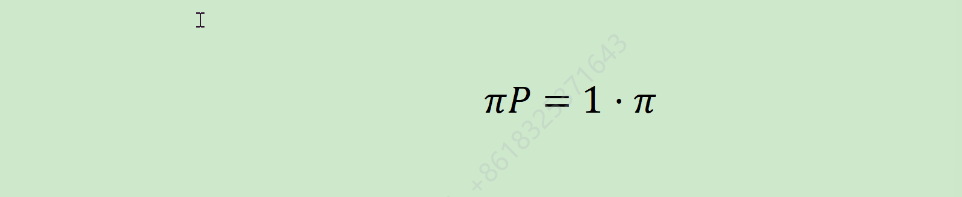
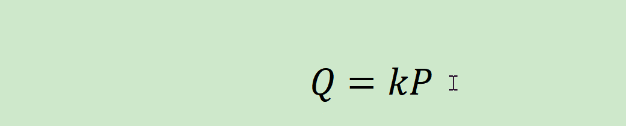
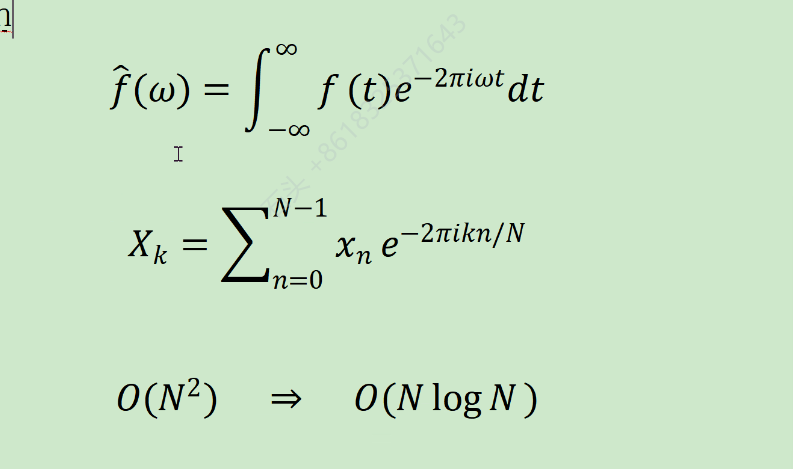

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

print("success")

success


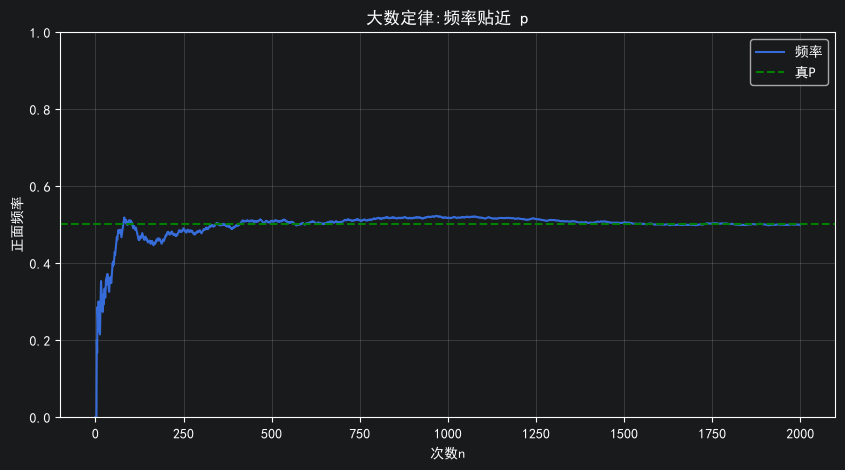

最终的频率 0.499


In [3]:
np.random.seed(0)
p_true = 0.5
N = 2000
flips = np.random.rand(N) < p_true
freq = np.cumsum(flips) / np.arange(1, N + 1)
plt.figure(figsize=(10, 5))
plt.plot(freq, label='频率')
plt.axhline(p_true, color='g', ls='--', label='真P')
plt.ylim(0, 1)
plt.xlabel('次数n')
plt.ylabel('正面频率')
plt.legend()
plt.title('大数定律:频率贴近 p')
plt.grid(True, alpha=0.3)
plt.show()

print("最终的频率", freq[-1])

### 独立同分布


In [5]:
np.random.seed(1)
rolls = np.random.randint(1, 7, size=2000)
means = np.cumsum(rolls) / np.arange(1, len(rolls) + 1)


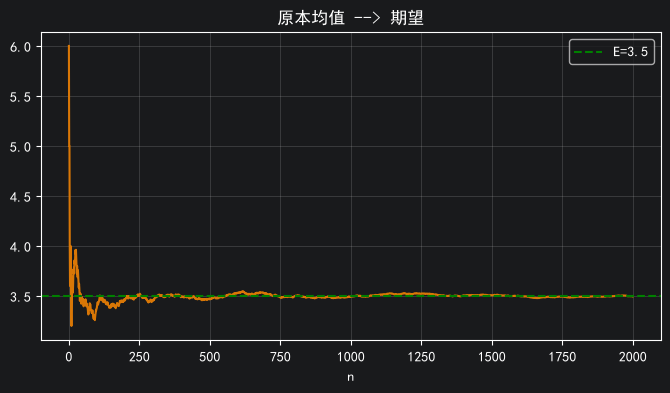

In [19]:
plt.figure(figsize=(8, 4))
plt.plot(means, color='#d97706')
plt.axhline(3.5, color='g', ls='--', label='E=3.5')
plt.xlabel('n')
plt.legend()
plt.title('原本均值 --> 期望')
plt.grid(True, alpha=0.3)
plt.show()

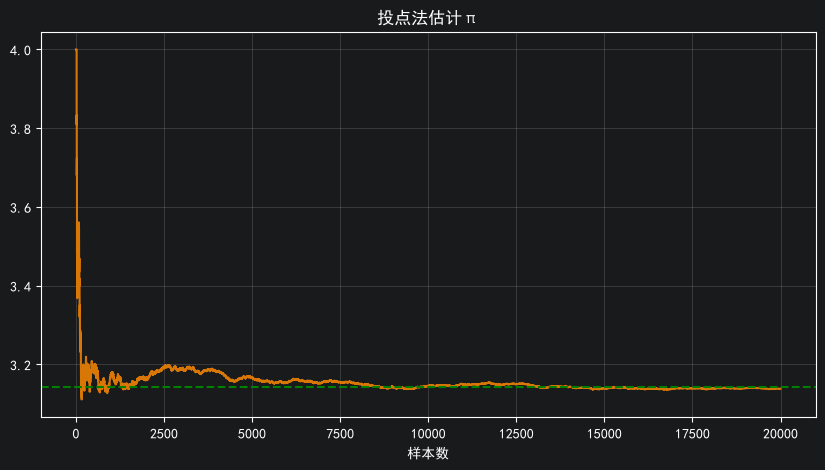

In [13]:
# 蒙特卡洛估计π
np.random.seed(2)
n = 20000
xy = np.random.rand(n, 2)
inside = (xy[:, 0] ** 2 + xy[:, 1] ** 2) <= 1
pi_test = 4 * np.cumsum(inside) / np.arange(1, n + 1)
plt.figure(figsize=(10, 5))
plt.plot(pi_test, color='#d97706')
plt.axhline(np.pi, color='g', ls='--', label='pi')
plt.title("投点法估计π")
plt.xlabel('样本数')
plt.grid(True, alpha=0.3)
plt.show()

In [15]:
print("估计π", pi_test[-1], f'真π:{np.pi}')

估计π 3.1382 真π:3.141592653589793


In [18]:
def mean_spread(n, trials=500):
    return np.array([(np.random.randn(n) <0.5).mean() for _ in range(trials)])


for n in [10,100,1000]:
    s = mean_spread(n)
    print(f"n={n:4d} 均值的标准差≈{s.std():.4f} (理论≈0.5/sqrt(n)={0.5/np.sqrt(n):.4f})")


n=  10 均值的标准差≈0.1450 (理论≈0.5/sqrt(n)=0.1581)
n= 100 均值的标准差≈0.0455 (理论≈0.5/sqrt(n)=0.0500)
n=1000 均值的标准差≈0.0151 (理论≈0.5/sqrt(n)=0.0158)


In [ ]:
# todo 手写蒙特卡洛